[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

构建参数化 ansatz，用经典优化器最小化能量。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 变分量子线路

In [1]:
import numpy as np
from scipy.optimize import minimize
from pyqpanda3.core import X, RY, CNOT, QProg
from pyqpanda3.core import expval_hamiltonian
from pyqpanda3.vqcircuit import VQCircuit
from pyqpanda3.hamiltonian import Hamiltonian

**构建哈密顿量**

$$
\begin{align}
H &= -1.052373 I_0 \otimes I_1 + 0.397937 Z_0 \otimes I_1 - 0.397937 I_0 \otimes Z_1 - 0.011280 Z_0 \otimes Z_1 + 0.180931 X_0 \otimes X_1 \\
&= -1.052373 \begin{bmatrix} 1&0&0&0\\ 0&1&0&0 \\ 0&0&1&0 \\ 0&0&0&1 \\ \end{bmatrix} + 0.397937 \begin{bmatrix} 1&0&0&0\\ 0&1&0&0 \\ 0&0&-1&0 \\ 0&0&0&-1 \\ \end{bmatrix} - 0.397937 \begin{bmatrix} 1&0&0&0\\ 0&-1&0&0 \\ 0&0&1&0 \\ 0&0&0&-1 \\ \end{bmatrix} - 0.011280 \begin{bmatrix} 1&0&0&0\\ 0&-1&0&0 \\ 0&0&-1&0 \\ 0&0&0&1 \\ \end{bmatrix} + 0.180931 \begin{bmatrix} 0&0&0&1\\ 0&0&1&0 \\ 0&1&0&0 \\ 1&0&0&0 \\ \end{bmatrix} \\
&= \begin{bmatrix} -1.063653&0&0&0.180931\\ 0&-0.245219&0.180931&0 \\ 0&0.180931&-1.836967&0 \\ 0.180931&0&0&-1.063653 \\ \end{bmatrix}
\end{align}
$$

In [2]:
def step1_define_hamiltonian() -> Hamiltonian:
    # 字典构造法
    hamiltonian = Hamiltonian(
        {
            "I0 I1": -1.052373,
            "Z0": 0.397937,
            "Z1": -0.397937,
            "Z0 Z1": -0.011280,
            "X0 X1": 0.180931
        }
    )

    # 列表构造法
    hamiltonian = Hamiltonian(
        ["I0 I1", "Z0", "Z1", "Z0 Z1", "X0 X1"],
        [-1.052373, 0.397937, -0.397937, -0.011280, 0.180931]
    )
    return hamiltonian

**构建量子态**

$$
|00\rangle \xrightarrow{X_0} |10\rangle \xrightarrow{RY(1, \theta)}  \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |11\rangle \xrightarrow{CNOT(1, 0)} \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle
$$

$$
|\psi(\theta)\rangle = \cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle
$$

In [3]:
def step2_build_ansatz(params) -> QProg:
    ansatz = QProg()
    ansatz << X(0) << RY(1, params[0]) << CNOT(1, 0)
    return ansatz

指定参数 $\theta$ 的值，计算哈密顿量期望值

In [4]:
def step3_get_expectation(params):
    hamiltonian = step1_define_hamiltonian()
    ansatz = step2_build_ansatz(params)
    expectation = expval_hamiltonian(ansatz, hamiltonian)
    return expectation

理论值

$$
\begin{align}
\langle H \rangle &= \langle H(\theta) \rangle \\
&= \langle \psi(\theta)| H | \psi(\theta)\rangle \\
&= \left(\cos \frac{\theta}{2} \langle 10| + \sin \frac{\theta}{2} \langle01|\right) H \left(\cos \frac{\theta}{2} |10\rangle + \sin \frac{\theta}{2} |01\rangle\right) \\
&= \begin{bmatrix}0&\sin\frac{\theta}{2}&\cos\frac{\theta}{2}&0\end{bmatrix} \begin{bmatrix} -1.063653&0&0&0.180931\\ 0&-0.245219&0.180931&0 \\ 0&0.180931&-1.836967&0 \\ 0.180931&0&0&-1.063653 \\ \end{bmatrix} \begin{bmatrix}0\\ \sin\frac{\theta}{2}\\ \cos\frac{\theta}{2}\\0\end{bmatrix} \\
&= \begin{bmatrix}0&\sin\frac{\theta}{2}&\cos\frac{\theta}{2}&0\end{bmatrix} \begin{bmatrix}0\\ -0.245219\sin\frac{\theta}{2}+0.180931\cos\frac{\theta}{2} \\ 0.180931\sin\frac{\theta}{2}-1.836967\cos\frac{\theta}{2}\\0\end{bmatrix} \\
&= -0.245219 \sin^2\frac{\theta}{2} + 0.180931\sin\theta -1.836967\cos^2\frac{\theta}{2} \\
&= 0.180931\sin\theta-0.795874\cos\theta - 1.041093 \\
&= 0.816181\sin(\theta-\theta_0) - 1.041093
\end{align}
$$

其中，$\theta_0 = \tan^{-1}(0.795874/0.180931) = 1.347259$.

显然，当 
$$
\theta-\theta_0 = -\frac{\pi}{2} + 2n\pi, n\in \mathbb{N}
$$

即
$$
\theta = -0.223536 + 2n\pi, n\in \mathbb{N}
$$

$\langle H(\theta)\rangle$ 取最小值 $-0.816181-1.041093=-1.857274$

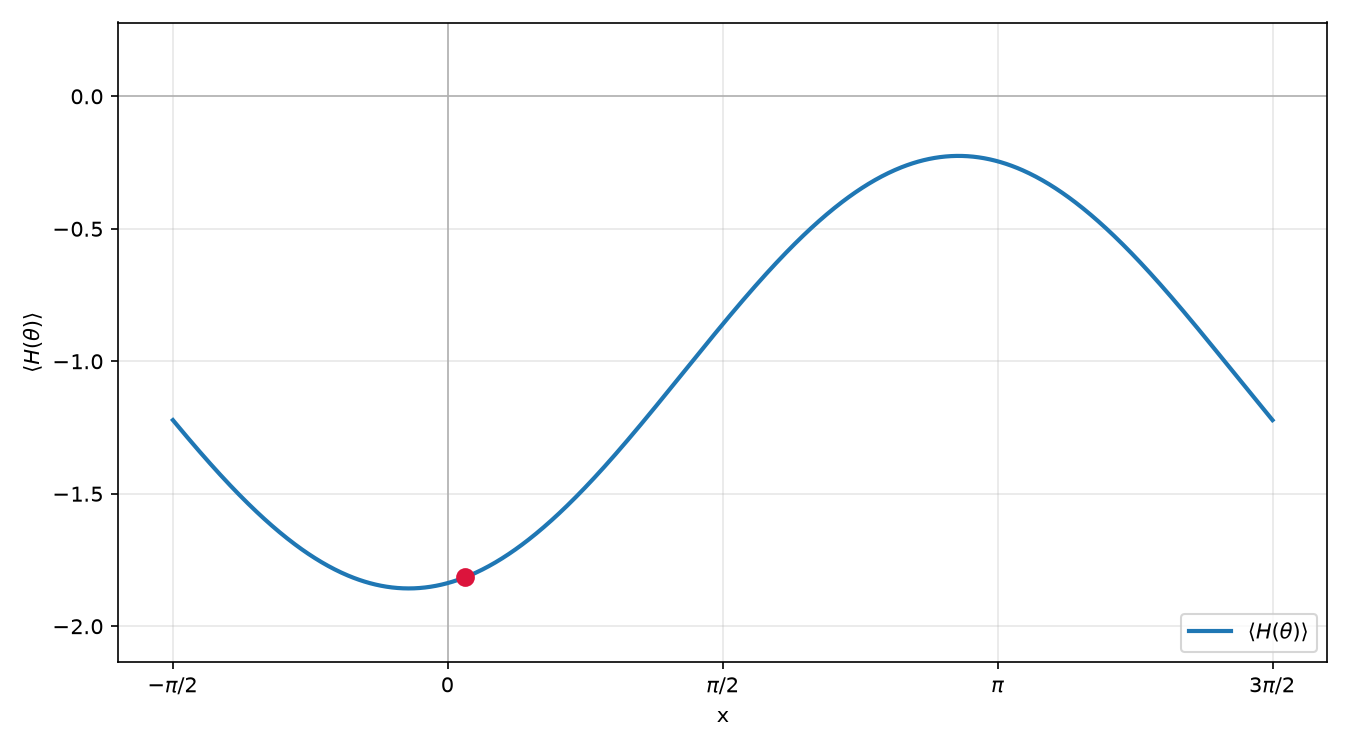

In [5]:
initial_guess = np.array([0.1])
result = minimize(
    step3_get_expectation,
    initial_guess,
    method='COBYLA',
    options={'maxiter': 200}
)
print(result)
print(f"Minimum energy: {result.fun:.6f}")
print(f"Optimal parameters: {result.x}")

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -1.857274015293491
       x: [-2.235e-01]
    nfev: 24
   maxcv: 0.0
Minimum energy: -1.857274
Optimal parameters: [-0.2235]


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

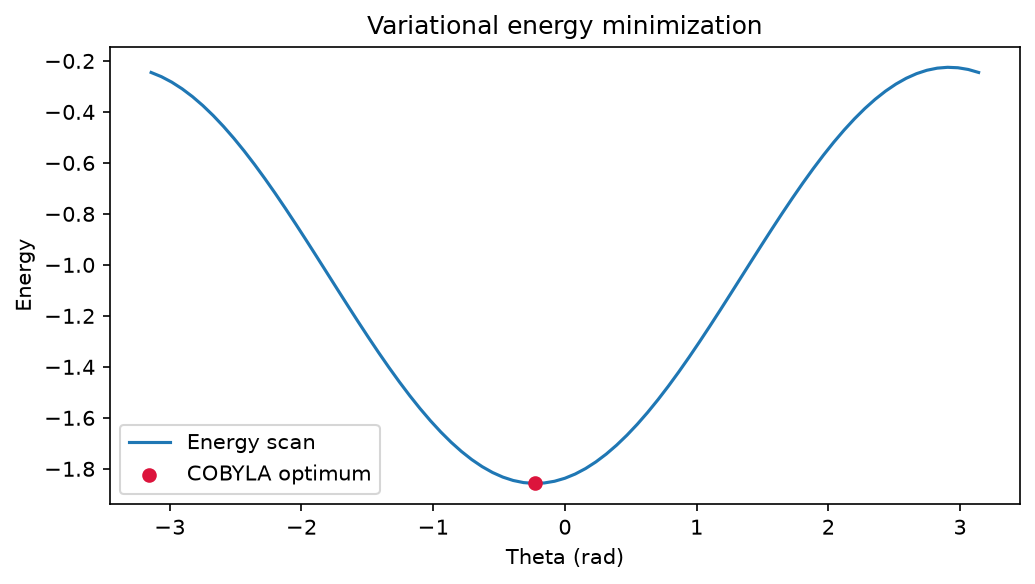

In [6]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

theta_grid = np.linspace(-np.pi, np.pi, 81)
energy_grid = [step3_get_expectation([theta]) for theta in theta_grid]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(theta_grid, energy_grid, label="Energy scan")
ax.scatter(result.x, [result.fun], color="crimson", zorder=3, label="COBYLA optimum")
ax.set(xlabel="Theta (rad)", ylabel="Energy", title="Variational energy minimization")
ax.legend()
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))
